In [2]:
import numpy as np
import matplotlib.pyplot as plt
from typing import Callable, Optional, Tuple, Dict, Any, List
import time
import math
import random

## MLP Solver

In [3]:
class MLPSolver:
    """
    Multilevel Picard (MLP) Solver for High-Dimensional Semilinear Heat PDEs.
    
    Implements Theorem 1.1 from Hutzenthaler et al. (2020).
    """
    def __init__(
        self,
        f: Callable[[float, np.ndarray, float], float],
        g: Callable[[np.ndarray], float],
        T: float = 0.5,
    ):
        """
        Parameters
        ----------
        f : Callable[[float, np.ndarray, float], float]
            Nonlinearity f(t, x, v) of the PDE.
        g : Callable[[np.ndarray], float]
            Terminal condition g(x).
        T : float
            Terminal time T > 0.
        seed : int, optional
            Random seed for reproducibility.
        """
        self.f = f
        self.g = g
        self.T = float(T)
        self.rng = np.random.default_rng()

    def solve(
        self,
        t: float,
        x: np.ndarray,
        n: int,
        M: int,
        rng: Optional[np.random.Generator] = None
    ) -> float:
        """
        Recursively calculates the MLP approximation U_{n, M}(t, x).

        Parameters
        ----------
        t : float
            Current time in [0, T].
        x : np.ndarray
            Spatial point of dimension d.
        n : int
            MLP level parameter (n >= 0).
        M : int
            Branching / Monte Carlo sample parameter (M >= 1).
        rng : np.random.Generator, optional
            RNG instance for recursive subtrees.

        Returns
        -------
        float
            Approximated solution value U_{n, M}(t, x).
        """
        if rng is None:
            rng = self.rng

        # Base case
        if n <= 0:
            return 0.0

        x = np.asarray(x, dtype=np.float64)
        d = len(x)
        dt = self.T - t

        # --- 1. Terminal condition Monte Carlo sum (M^n samples) ---
        M_n = M**n
        if dt > 0:
            Z_terminal = rng.standard_normal((M_n, d))
            X_terminal = x + np.sqrt(dt) * Z_terminal
        else:
            X_terminal = np.tile(x, (M_n, 1))

        g_vals = np.array([self.g(X_terminal[i]) for i in range(M_n)])
        term_g = np.mean(g_vals)

        # --- 2. Multilevel Picard sum over levels l = 0, ..., n-1 ---
        term_f = 0.0
        for l in range(n):
            M_nl = M**(n - l)

            # Draw uniform random times R_t ~ U[t, T]
            r = rng.uniform(0.0, 1.0, size=M_nl)
            R_t = t + dt * r
            dtau = R_t - t

            # Draw Brownian motion increments
            Z = rng.standard_normal((M_nl, d))
            X_R = x + np.sqrt(dtau[:, None]) * Z

            diff_sum = 0.0
            for i in range(M_nl):
                t_sample = R_t[i]
                x_sample = X_R[i]

                # Evaluate U_{l, M}(t_sample, x_sample)
                val_l = self.solve(t_sample, x_sample, l, M, rng=rng)
                f_l = self.f(t_sample, x_sample, val_l)

                # Evaluate U_{l-1, M}(t_sample, x_sample) for l > 0
                if l > 0:
                    val_l_minus_1 = self.solve(t_sample, x_sample, l - 1, M, rng=rng)
                    f_l_minus_1 = self.f(t_sample, x_sample, val_l_minus_1)
                else:
                    f_l_minus_1 = 0.0

                diff_sum += (f_l - f_l_minus_1)

            term_f += dt * (diff_sum / M_nl)

        return term_g + term_f
    
    def compute_cost(self, n: int, M: int, d: int) -> int:
        """
        Calculates the theoretical computational cost (total number of scalar random
        variable realizations) required to evaluate U_{n, M}(t, x).

        Parameters
        ----------
        n : int
            MLP level parameter (n >= 0).
        M : int
            Branching / Monte Carlo sample parameter (M >= 1).
        d : int
            Spatial dimension of vector x.

        Returns
        -------
        int
            Total number of scalar random variable realizations.
        """
        if n <= 0:
            return 0

        # Terminal condition cost: d * M^n standard normal random variables
        cost = d * (M**n)

        # Multilevel Picard recursion cost over levels l = 0, ..., n-1
        for l in range(n):
            M_nl = M**(n - l)
            # Per sample cost:
            # - 1 uniform random time draw
            # - d standard normal spatial increments
            # - solve(l, M) cost
            # - solve(l-1, M) cost (for l > 0)
            sample_cost = (d + 1) + self.compute_cost(l, M, d)
            if l > 0:
                sample_cost += self.compute_cost(l - 1, M, d)

            cost += M_nl * sample_cost

        return cost

    def evaluate_trials(
        self,
        t: float,
        x: np.ndarray,
        n: int,
        M: int,
        num_trials: int = 10
    ) -> Dict[str, float]:
        """
        Runs multiple independent realizations to estimate mean and standard error.
        """
        results = [self.solve(t, x, n, M) for _ in range(num_trials)]
        return {
            "mean": float(np.mean(results)),
            "std": float(np.std(results, ddof=1)),
            "sem": float(np.std(results, ddof=1) / np.sqrt(num_trials)),
            "trials": results
        }

## Test

In [4]:
def create_benchmark_pde(d: int, T: float = 0.5, lambda_param: float = 1.0):
    """
    Creates benchmark f, g, and exact solution functions for a d-dimensional PDE.
    """
    scale = 1.0 / np.sqrt(d)

    def u_exact(t: float, x: np.ndarray) -> float:
        y = np.sum(x) * scale
        return np.cos(y) * np.exp(T - t)

    def g(x: np.ndarray) -> float:
        y = np.sum(x) * scale
        return np.cos(y)

    def f(t: float, x: np.ndarray, v: float) -> float:
        u_val = u_exact(t, x)
        source_term = 1.5 * u_val - lambda_param * np.sin(u_val)
        return lambda_param * np.sin(v) + source_term

    return f, g, u_exact

In [5]:
# Configuration parameters
d = 100
T = 0.5
n_level = 3
M_branch = 4
num_trials = 150

f, g, u_exact = create_benchmark_pde(d=d, T=T)
solver = MLPSolver(f=f, g=g, T=T)

x0 = np.zeros(d)
exact_val = u_exact(0.0, x0)

print("=" * 65)
print(f"MLP SOLVER BENCHMARK: PDE Dimension d = {d}, T = {T}")
print(f"Exact Solution u(0, 0) = {exact_val:.6f}")
print("=" * 65)

# Evaluate convergence over levels n = 1, 2, 3
for level in range(1, n_level + 1):
    t0 = time.time()
    res = solver.evaluate_trials(0.0, x0, n=level, M=M_branch, num_trials=num_trials)
    elapsed = time.time() - t0
    
    abs_err = abs(res['mean'] - exact_val)
    rel_err = abs_err / abs(exact_val)
    
    print(f"Level n={level} | M={M_branch} | MLP Mean: {res['mean']:.6f} +/- {res['sem']:.6f} "
          f"| Abs Error: {abs_err:.6f} | Rel Error: {rel_err:.2%} | Time: {elapsed:.2f}s")

MLP SOLVER BENCHMARK: PDE Dimension d = 100, T = 0.5
Exact Solution u(0, 0) = 1.648721
Level n=1 | M=4 | MLP Mean: 1.221154 +/- 0.012994 | Abs Error: 0.427567 | Rel Error: 25.93% | Time: 0.01s
Level n=2 | M=4 | MLP Mean: 1.621376 +/- 0.006325 | Abs Error: 0.027345 | Rel Error: 1.66% | Time: 0.04s
Level n=3 | M=4 | MLP Mean: 1.642388 +/- 0.003903 | Abs Error: 0.006333 | Rel Error: 0.38% | Time: 0.22s


In [195]:
d = 1
T = 0.5
n_level = 2
M_branch = 1
num_trials = 20

def g_n(x: np.ndarray) -> float:
    return 1

def f_n(t: float, x: np.ndarray, v: float) -> float:
    return np.sin(v+x) 

solver = MLPSolver(f=f_n, g=g_n, T=T)
res = solver.evaluate_trials(0, [0.5], n=level, M=M_branch, num_trials=num_trials)
print(res['trials'])
print(res['mean'])

[array([1.17164697]), array([1.21197256]), array([1.71162129]), array([1.27968126]), array([1.77636881]), array([1.39978058]), array([1.51638592]), array([1.13928758]), array([1.59827005]), array([1.29546912]), array([1.49020957]), array([1.62818801]), array([1.35915857]), array([1.13755195]), array([1.60853392]), array([1.43922239]), array([1.36445982]), array([0.82043542]), array([1.41262791]), array([1.22522675])]
1.3793049239725979


## RMSE vs Bias

first part


/Users/khoatran/Documents/Research/Quantum-Picard/Code/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Users/khoatran/Documents/Research/Quantum-Picard/Code/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:211: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


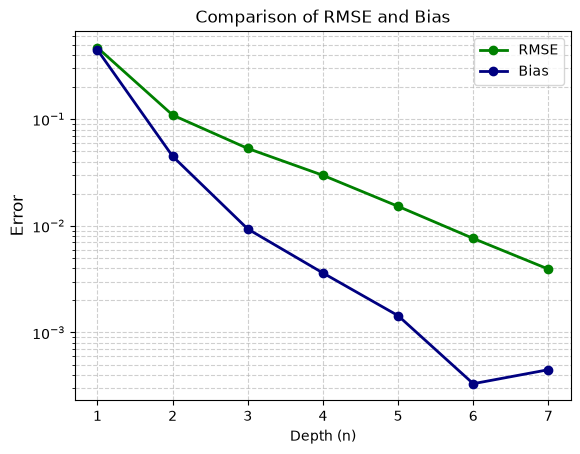

In [60]:
fig, ax = plt.subplots()

d_test = 10
input_test = [random.uniform(-0.5, 0.5) for i in range(d_test)]
f_10, g_10, u_ex_10 = create_benchmark_pde(d=d_test, T=T)
solver_10 = MLPSolver(f=f_10, g=g_10, T=T, seed=123)
exact_10 = u_ex_10(0.0, input_test)

levels = [i for i in range(1, 8)]
n_rmse = []
n_bias = []

for n in levels:
    res = solver_10.evaluate_trials(0.0, input_test, n=n, M=4, num_trials=100)
    n_bias.append(abs(res['mean'] - exact_10))

print("first part")

for n in levels:
    sq_err = 0.0
    tries = 100
    for j in range(tries):
        res = solver_10.evaluate_trials(0.0, input_test, n=n, M=4, num_trials=1)
        sq_err += abs(res['mean'] - exact_10)**2
    n_rmse.append(math.sqrt(sq_err/tries))

ax.plot(levels, n_rmse, 'o-', label='RMSE', color='green', lw=2)
ax.plot(levels, n_bias, 'o-', label='Bias', color='navy', lw=2)

ax.set_xlabel('Depth (n)')
ax.set_yscale('log')
ax.set_ylabel('Error', fontsize=12)
ax.set_title('Comparison of RMSE and Bias', fontsize=12)
ax.grid(True, which="both", ls="--", alpha=0.6)
ax.legend()

plt.show()


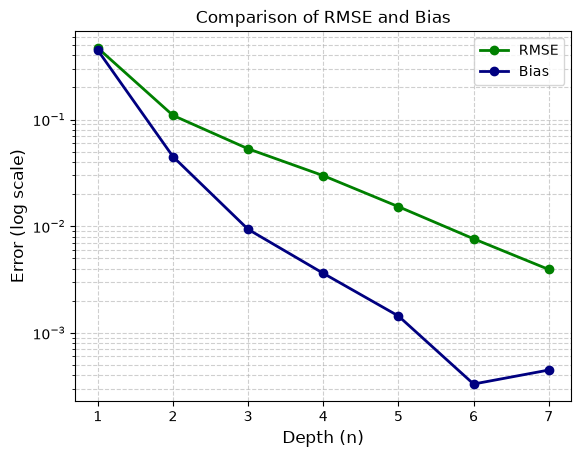

In [62]:
fig, ax = plt.subplots()

ax.plot(levels, n_rmse, 'o-', label='RMSE', color='green', lw=2)
ax.plot(levels, n_bias, 'o-', label='Bias', color='navy', lw=2)

ax.set_xlabel('Depth (n)', fontsize=12)
ax.set_yscale('log')
ax.set_ylabel('Error (log scale)', fontsize=12)
ax.set_title('Comparison of RMSE and Bias', fontsize=12)
ax.grid(True, which="both", ls="--", alpha=0.6)
ax.legend()

plt.show()

## No curse of dimensionality

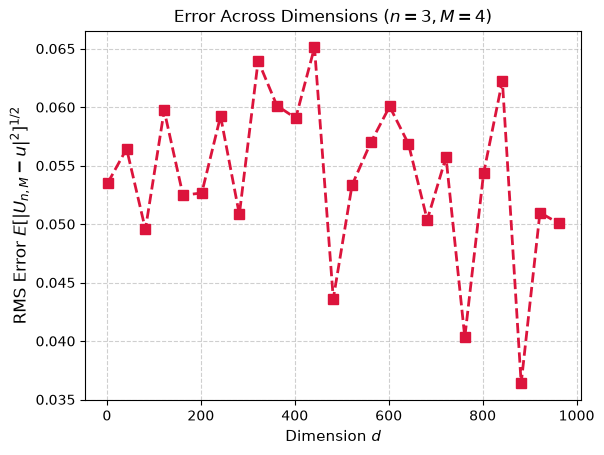

In [21]:
fig, ax = plt.subplots()

d_errors = []

dimensions = [i for i in range(2, 1000, 40)]
for d in dimensions:
    input_x = [random.uniform(-0.5, 0.5) for i in range(d)]
    f_d, g_d, u_ex_d = create_benchmark_pde(d=d, T=T)
    solver_d = MLPSolver(f=f_d, g=g_d, T=T, seed=42)
    exact_d = u_ex_d(0.0, input_x)
    sq_err = 0.0
    for j in range(30):
        sq_err += (solver_d.evaluate_trials(0.0, input_x, n=3, M=4, num_trials=1)['mean'] - exact_d)**2
        
    d_errors.append(math.sqrt(sq_err/30))

ax.plot(dimensions, d_errors, 's--', color='crimson', lw=2, markersize=7)
ax.set_xlabel(r'Dimension $d$', fontsize=11)
ax.set_ylabel(r'RMS Error $E[|U_{n,M} - u|^2]^{1/2}$', fontsize=12)
ax.set_title(r'Error Across Dimensions ($n=3, M=4$)', fontsize=12)
ax.grid(True, which="both", ls="--", alpha=0.6)

## RMSE vs Cost

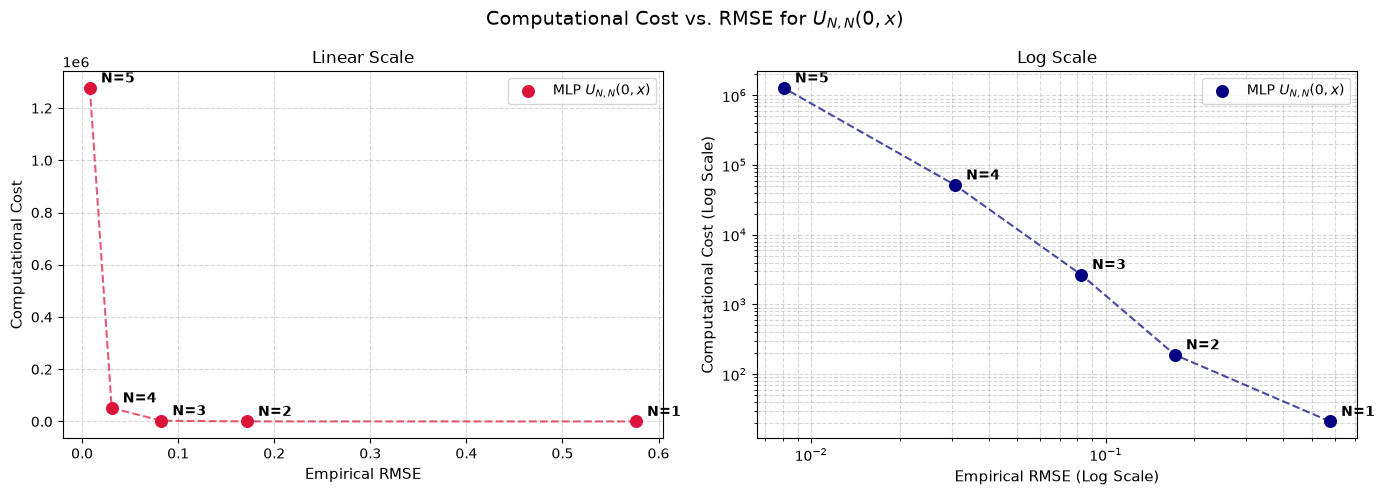

In [8]:
d_test = 10
T = 0.5
input_test = [random.uniform(-0.5, 0.5) for i in range(d_test)]
f_10, g_10, u_ex_10 = create_benchmark_pde(d=d_test, T=T)
solver_10 = MLPSolver(f=f_10, g=g_10, T=T)
exact_10 = u_ex_10(0.0, input_test)

depths = [i for i in range(1, 6)]
rmses = []
costs = []

for N in depths:
    solver = MLPSolver(f=f_10, g=g_10, T=T)
    costs.append(solver.compute_cost(n=N, M=N, d=d_test))
    trials = [solver.solve(t=0.0, x=input_test, n=N, M=N) for _ in range(50)]
    rmses.append(np.sqrt(np.mean((np.array(trials) - exact_10)**2)))

# --- Side-by-Side Plotting ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Completely Linear Scale
ax1.scatter(rmses, costs, color='crimson', s=70, zorder=3, label=r'MLP $U_{N,N}(0, x)$')
ax1.plot(rmses, costs, linestyle='--', color='crimson', alpha=0.7)

for N, err, cost in zip(depths, rmses, costs):
    ax1.annotate(f'N={N}', (err, cost), textcoords="offset points", xytext=(8, 4), fontsize=10, weight='bold')

ax1.set_xlabel('Empirical RMSE', fontsize=11)
ax1.set_ylabel('Computational Cost', fontsize=11)
ax1.set_title('Linear Scale', fontsize=12)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(fontsize=10)

# Subplot 2: Log Scale for Error Only
ax2.scatter(rmses, costs, color='navy', s=70, zorder=3, label=r'MLP $U_{N,N}(0, x)$')
ax2.plot(rmses, costs, linestyle='--', color='navy', alpha=0.7)
ax2.set_xscale('log')
ax2.set_yscale('log')

for N, err, cost in zip(depths, rmses, costs):
    ax2.annotate(f'N={N}', (err, cost), textcoords="offset points", xytext=(8, 4), fontsize=10, weight='bold')

ax2.set_xlabel('Empirical RMSE (Log Scale)', fontsize=11)
ax2.set_ylabel('Computational Cost (Log Scale)', fontsize=11)
ax2.set_title('Log Scale', fontsize=12)
ax2.grid(True, which="both", linestyle="--", alpha=0.5)
ax2.legend(fontsize=10)

plt.suptitle(r'Computational Cost vs. RMSE for $U_{N,N}(0, x)$', fontsize=14)
plt.tight_layout()
plt.show()

## 3D Plot

In [18]:
def run_experiment_1_3d_plot(
    n: int = 3,
    M: int = 4,
    d: int = 1,
    T: float = 0.5,
    num_grid_t: int = 15,
    num_grid_x: int = 21,
    num_trials_per_point: int = 5,
    seed: int = 42
) -> None:
    """
    Experiment 1: 3D Surface plot comparing True Solution vs. MLP Algorithm
    over [0, 0.5] x [-1, 1] for n=3, M=4, d=1.
    """
    print("Running Experiment 1: 3D Surface Plot Comparison...")
    f, g, u_exact = create_benchmark_pde(d=d, T=T)
    solver = MLPSolver(f=f, g=g, T=T, seed=seed)

    t_vals = np.linspace(0.0, T, num_grid_t)
    x_vals = np.linspace(-1.0, 1.0, num_grid_x)
    T_grid, X_grid = np.meshgrid(t_vals, x_vals)

    U_exact_mesh = np.zeros_like(T_grid)
    U_mlp_mesh = np.zeros_like(T_grid)

    for i in range(X_grid.shape[0]):
        for j in range(X_grid.shape[1]):
            t_curr = T_grid[i, j]
            x_curr = np.array([X_grid[i, j]])

            U_exact_mesh[i, j] = u_exact(t_curr, x_curr)
            
            # Average over a few trials to reduce sampling noise on surface
            mlp_vals = [solver.solve(t_curr, x_curr, n=n, M=M) for _ in range(num_trials_per_point)]
            U_mlp_mesh[i, j] = np.mean(mlp_vals)

    fig = plt.figure(figsize=(12, 6))

    # True Solution Surface
    ax1 = fig.add_subplot(121, projection='3d')
    surf1 = ax1.plot_surface(T_grid, X_grid, U_exact_mesh, cmap='viridis', alpha=0.85, edgecolor='k', lw=0.2)
    ax1.set_title("Exact Solution $u(t, x)$")
    ax1.set_xlabel("$t$")
    ax1.set_ylabel("$x$")
    #ax1.set_zlabel("$u(t, x)$")
    fig.colorbar(surf1, ax=ax1, shrink=0.5, aspect=10)

    # MLP Approximation Surface
    ax2 = fig.add_subplot(122, projection='3d')
    surf2 = ax2.plot_surface(T_grid, X_grid, U_mlp_mesh, cmap='plasma', alpha=0.85, edgecolor='k', lw=0.2)
    ax2.set_title(f"MLP Approximation $U_{{{n}, {M}}}(t, x)$ ($n={n}, M={M}$)")
    ax2.set_xlabel("$t$")
    ax2.set_ylabel("$x$")
    #ax2.set_zlabel("$U(t, x)$")
    fig.colorbar(surf2, ax=ax2, shrink=0.5, aspect=10)

    plt.suptitle("PDE Solution vs MLP Approximation over $[0, 0.5] \\times [-1, 1]$ ($d=1$)", fontsize=14)
    plt.tight_layout()
    plt.show()

Running Experiment 1: 3D Surface Plot Comparison...


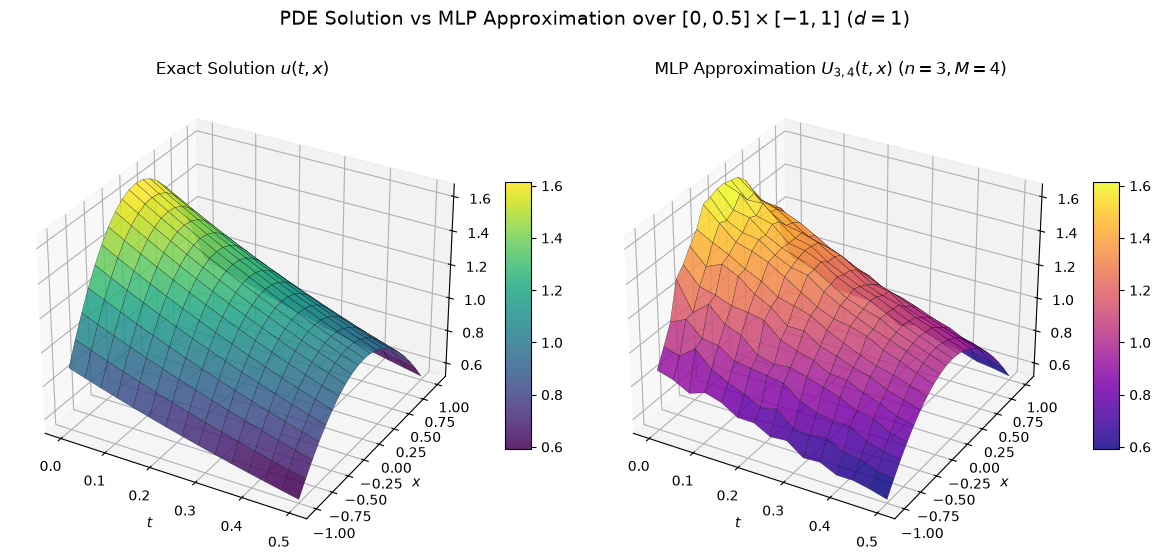

In [19]:
run_experiment_1_3d_plot()